# Which genes drive the oligodendrocyte mtDSB response?

Follows `02-ol-response-and-classifiers.ipynb` (responders RB4405, RB4401, RB4627; non-responders RB4403,
RB4630, RB4653). Inputs, produced on the office Mac by `scripts/run_ol_gene_drivers.py`:

* `results/ol_gene_drivers/coefficients.csv.gz`: gene weights of every fold model of the OL single-cell
  classifier (general labels): pooled `condition` (12 leave-one-section-out folds), and two cohort models
  trained on disjoint animals (`condition 21->60`: the 6 P21 mice; `condition 60->21`: the 6 P60 mice).
* `results/ol_gene_drivers/association.csv.gz`: per section, the Pearson correlation across individual OLs
  between each gene and the cell's out-of-fold p(mtDSB). Being *within* a section, it is immune to
  section-level differences (batch, plane, time of sacrifice).

**Rule for a "driver" gene (fixed before inspecting the gene list):** within-section r > 0.1 in *each* of the
three responders, and mean r < 0.1 in both controls and non-responders (mirror rule for down genes:
r < -0.1 in each responder, > -0.1 in controls and non-responders).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

REPO = Path.cwd().resolve().parent
sys.path.insert(0, str(REPO))
from utils import ol_response as olr
from utils.region_time_de import TISSUE_WIDE, Pseudobulk

GD = REPO / "results" / "ol_gene_drivers"
FIG = GD / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = GD / "tables"; TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
sections["age"] = sections["age"].astype(str)
coefs = pd.read_csv(GD / "coefficients.csv.gz")
assoc_long = pd.read_csv(GD / "association.csv.gz")
pb = olr.general_pseudobulk(Pseudobulk.load(REPO / "results" / "region_time"))

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#d95926"])
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df

# gene programmes (manual annotation of the driver genes; see markdown in section 3)
PROGRAMME = {
    "ATF4 / integrated stress response": ["Atf4", "Atf5", "Ddit3", "Trib3", "Cebpg", "Sesn2", "Yars", "Vegfa"],
    "mitochondrial & protein quality control": ["Hspa9", "Sqstm1", "Lamp2", "Nfe2l1", "Gstp1", "Mt2"],
    "cell cycle / survival": ["Cdkn1a", "Ccnd1", "Myc", "Bcl2l1"],
    "immune / reactive": ["H2-D1", "B2m", "Cd40", "Serpina3n", "Adamts1"],
    "OL lineage / immature": ["Olig2", "Adgrg1"],
    "cytoskeleton / adhesion": ["Flna", "Msn", "Coro1c", "Mpzl1", "Ptpra"],
    "lipid / transport": ["Abca1", "Slc6a8"],
    "mature OL / myelin (down)": ["Cldn11", "Mog", "Mal", "Cnp", "Ugt8a", "Tppp", "Stmn4", "Aplp1", "Mapk8ip1"],
}
GENE2PROG = {g: p for p, gs in PROGRAMME.items() for g in gs}
GLUCOCORTICOID = ["Sgk1", "Fkbp5", "Zbtb16", "Plin4", "Arrdc2", "Klf9", "Per1", "Tsc22d3"]

## 1. Within-section association: what separates stressed from unstressed OLs in the same tissue

In [2]:
asum = olr.summarize_association(assoc_long, sections).set_index("gene")
resp_r = assoc_long.merge(sections[["group"]], left_on="sample_id", right_index=True)
max_r_resp = resp_r[resp_r.group == "responder"].pivot(index="gene", columns="sample_id", values="r").max(1)
asum["max_r_responders"] = max_r_resp
csum = olr.summarize_coefficients(coefs)
w = csum.pivot(index="gene", columns="task", values="mean_coef")
asum = asum.join(w.rename(columns=lambda c: f"weight[{c}]")).join(
    csum[csum.task == "condition"].set_index("gene")[["sign_consistency"]].rename(columns={"sign_consistency": "sign_consistency[condition]"}))

up = asum[(asum.min_r_responders > 0.1) & (asum.r_control < 0.1) & (asum["r_non-responder"] < 0.1)]
down = asum[(asum.max_r_responders < -0.1) & (asum.r_control > -0.1) & (asum["r_non-responder"] > -0.1)]
drivers = pd.concat([up.assign(direction="up"), down.assign(direction="down")])
drivers["programme"] = drivers.index.map(GENE2PROG).fillna("other")
drivers = drivers.sort_values(["direction", "r_responder"], ascending=[False, False])
save_table(drivers.round(4), "driver_genes")
save_table(asum.round(4), "all_genes_association_and_weights")
print(f"{len(up)} up, {len(down)} down driver genes")
display(drivers[["direction", "programme", "r_responder", "min_r_responders", "r_control", "r_non-responder",
                 "weight[condition]", "weight[condition 21->60]", "weight[condition 60->21]"]].round(3))

34 up, 9 down driver genes


,direction,programme,r_responder,min_r_responders,r_control,r_non-responder,weight[condition],weight[condition 21->60],weight[condition 60->21]
gene,,,,,,,,,
Trib3,up,ATF4 / integrated stress response,0.291,0.218,0.049,0.007,0.284,0.657,0.501
Cdkn1a,up,cell cycle / survival,0.237,0.181,0.055,0.045,0.212,0.146,0.367
Cd40,up,immune / reactive,0.235,0.154,0.042,0.020,0.136,0.280,0.223
Serpina3n,up,immune / reactive,0.229,0.191,0.075,0.056,0.200,0.165,0.018
Atf5,up,ATF4 / integrated stress response,0.222,0.210,0.069,0.056,0.187,0.327,0.485
Mt2,up,mitochondrial & protein quality control,0.218,0.216,0.088,0.077,0.303,0.510,0.822
Ccnd1,up,cell cycle / survival,0.209,0.127,0.045,0.026,0.081,0.454,0.057
Atf4,up,ATF4 / integrated stress response,0.207,0.172,0.020,0.022,0.018,0.170,-0.016
H2-D1,up,immune / reactive,0.193,0.163,0.052,0.044,0.090,0.406,-0.045


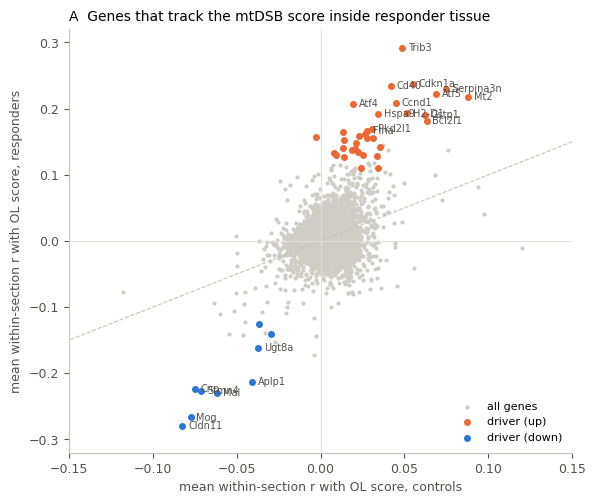

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(asum.r_control, asum.r_responder, s=4, color="#cfcdc6", rasterized=True, label="all genes")
for d, col in (("up", ORANGE), ("down", BLUE)):
    sub = drivers[drivers.direction == d]
    ax.scatter(sub.r_control, sub.r_responder, s=16, color=col, label=f"driver ({d})", zorder=3)
lab = pd.concat([drivers[drivers.direction == "up"].head(14), drivers[drivers.direction == "down"].sort_values("r_responder").head(7)])
for g, row in lab.iterrows():
    ax.annotate(g, (row.r_control, row.r_responder), xytext=(4, 0), textcoords="offset points", fontsize=7, color=INK2, va="center")
lim = (-0.32, 0.32)
ax.plot(lim, lim, color=AXIS, lw=0.8, ls="--")
ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
ax.set_xlim(-0.15, 0.15); ax.set_ylim(*lim)
ax.set_xlabel("mean within-section r with OL score, controls")
ax.set_ylabel("mean within-section r with OL score, responders")
ax.set_title("A  Genes that track the mtDSB score inside responder tissue")
ax.legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "G1_within_section_association")

## 2. Do the classifier's weights replicate across independent animals?

The two cohort models are trained on disjoint sets of 6 mice. Genome-wide the weights barely correlate
(most genes are uninformative noise), so the meaningful test is whether the *top* genes overlap.

,top_k,direction,overlap,expected,hypergeom_p,genes
0,25,up,5,0.1225,0.0000,Bcl2l1 Meg3 Mt2 Trib3 Zbtb16
1,25,down,1,0.1225,0.1158,Cldn11
2,50,up,10,0.4901,0.0000,A2m Atf5 Bcl2l1 Mc3r Meg3 Mt2 Plin4 Rnf144a Tr...
3,50,down,4,0.4901,0.0014,Cldn11 Il33 Opalin Vstm2a
4,100,up,15,1.9604,0.0000,A2m Arid5b Atf5 Bcl2l1 Cst7 Fkbp5 Hspa5 Mc3r M...
5,100,down,6,1.9604,0.0132,Cldn11 Gng11 Il33 Opalin Stmn4 Vstm2a


genome-wide Spearman between cohort models: 0.035


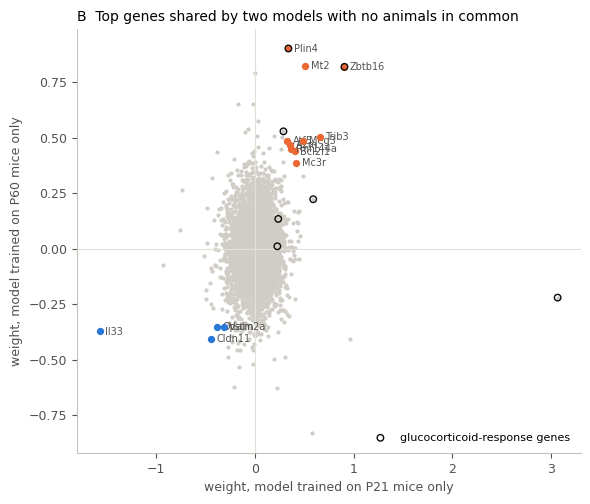

In [4]:
a, b = w["condition 21->60"], w["condition 60->21"]
rows = []
for k in (25, 50, 100):
    for d, fa, fb in (("up", a.nlargest, b.nlargest), ("down", a.nsmallest, b.nsmallest)):
        ov = set(fa(k).index) & set(fb(k).index)
        rows.append({"top_k": k, "direction": d, "overlap": len(ov), "expected": k * k / len(w),
                     "hypergeom_p": stats.hypergeom.sf(len(ov) - 1, len(w), k, k), "genes": " ".join(sorted(ov))})
rep = save_table(pd.DataFrame(rows), "cohort_weight_replication", index=False)
display(rep.round(4))
print("genome-wide Spearman between cohort models:", round(a.corr(b, method="spearman"), 3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(a, b, s=4, color="#cfcdc6", rasterized=True)
top_both = rep.query("top_k == 50").genes.str.split().sum()
for g in top_both:
    ax.scatter(a[g], b[g], s=18, color=ORANGE if a[g] > 0 else BLUE, zorder=3)
    ax.annotate(g, (a[g], b[g]), xytext=(4, 0), textcoords="offset points", fontsize=7, color=INK2, va="center")
gc = [g for g in GLUCOCORTICOID if g in w.index]
ax.scatter(a[gc], b[gc], s=22, facecolor="none", edgecolor=INK, zorder=4, label="glucocorticoid-response genes")
ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
ax.set_xlabel("weight, model trained on P21 mice only")
ax.set_ylabel("weight, model trained on P60 mice only")
ax.set_title("B  Top genes shared by two models with no animals in common")
ax.legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "G2_cohort_replication")

## 3. Driver genes per section: up in responders, flat in non-responders and controls

Oligodendrocyte pseudobulk (whole section), log2 fold change vs the mean of the six controls. The genes
group into programmes (manual annotation): the ATF4 / integrated stress response; mitochondrial and
protein quality control (Hspa9 = mortalin, Sqstm1 = p62, Lamp2, Nfe2l1); cell-cycle / survival
(Cdkn1a = p21, Ccnd1, Myc, Bcl2l1); immune / reactive (MHC class I H2-D1 and B2m, Cd40, Serpina3n);
and, going *down*, mature-OL / myelin genes (Cldn11, Mog, Mal, Cnp, Ugt8a, Tppp), while the lineage /
immature genes Olig2 and Adgrg1 go up.

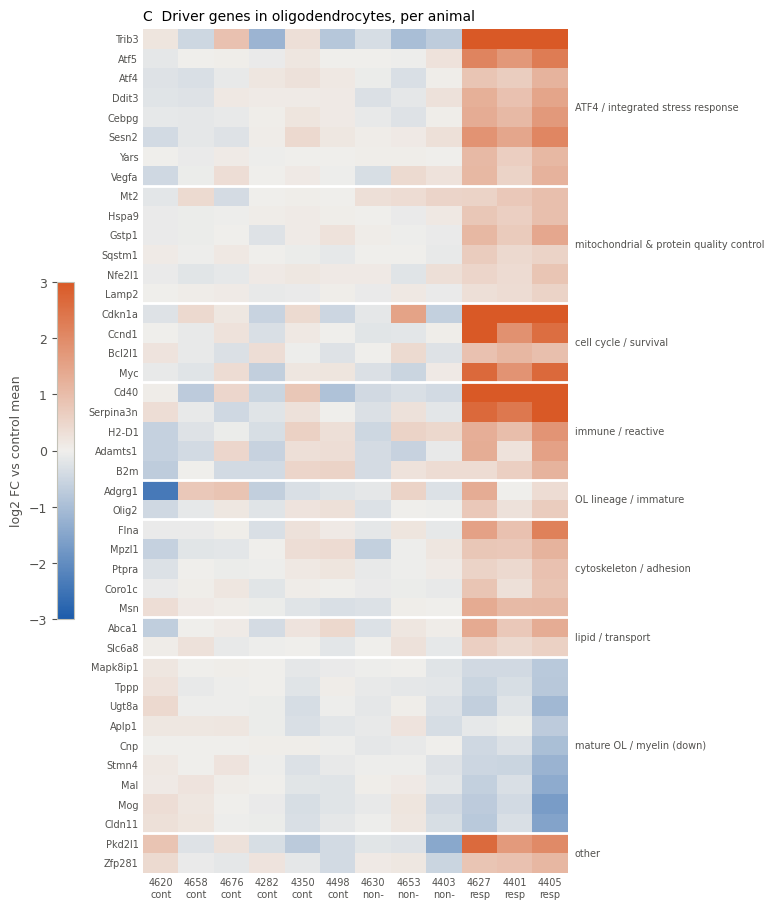

In [5]:
m = pb.meta
sel = (m.cell_type == olr.OL) & (m.region == TISSUE_WIDE)
c = pb.counts.loc[sel]; cpm = c.div(c.sum(1), axis=0) * 1e6; cpm.index = m.loc[sel, "sample_id"]
ctrl = sections.index[sections.group == "control"]
lfc = np.log2((cpm + 1) / (cpm.loc[ctrl].mean() + 1))
sec_order = sections.assign(o=sections.group.map({g: i for i, g in enumerate(GROUP_ORDER)})).sort_values(["o", "age"]).index
prog_order = list(PROGRAMME) + ["other"]
gene_order = drivers.assign(o=drivers.programme.map({p: i for i, p in enumerate(prog_order)})).sort_values(["o", "r_responder"], ascending=[True, False]).index
L = lfc.loc[sec_order, gene_order].T
save_table(L.round(3), "driver_genes_log2fc_by_section")

fig, ax = plt.subplots(figsize=(7.5, 0.22 * len(gene_order) + 1.5))
im = ax.imshow(L.to_numpy(), cmap=DIV, vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(len(gene_order)), [f"{g}" for g in gene_order], fontsize=7)
ax.set_xticks(range(len(sec_order)), [f"{s[2:]}\n{sections.loc[s, 'group'][:4]}" for s in sec_order], fontsize=7)
# programme separators and labels
progs = drivers.loc[gene_order, "programme"].to_numpy()
for i in range(1, len(progs)):
    if progs[i] != progs[i - 1]:
        ax.axhline(i - 0.5, color="white", lw=2)
starts = [0] + [i for i in range(1, len(progs)) if progs[i] != progs[i - 1]]
for st, en in zip(starts, starts[1:] + [len(progs)]):
    ax.text(len(sec_order) - 0.3, (st + en - 1) / 2, progs[st], fontsize=7, color=INK2, va="center", ha="left")
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.4, label="log2 FC vs control mean", location="left", pad=0.12)
ax.set_title("C  Driver genes in oligodendrocytes, per animal")
save(fig, "G3_driver_genes_by_section")

## 4. Region: are the drivers stronger in fiber tracts and thalamus?

Per region, the mean log2 fold change of the up-driver genes (excluding the myelin set) in each responder
vs the control mean of that region.

myelin_down                          \
group                              control non-responder responder   
region                                                               
Thalamus                             -0.01         -0.09     -0.77   
Fiber tracts                         -0.01         -0.09     -0.77   
Hypothalamus                         -0.01         -0.22     -0.62   
Cortex                               -0.01         -0.06     -0.66   
Striatum                             -0.01         -0.07     -0.64   
Ventricular system                   -0.01         -0.10     -0.67   
Hippocampus                          -0.02         -0.21     -0.53   
Meningeal border/glia limitans       -0.02         -0.05     -0.51   
Pallidum                             -0.01         -0.19     -0.34   
Vasculature                          -0.01          0.10     -0.28   
Olfactory areas                      -0.00         -0.11     -0.32   

                               up_programme                          
group                               control non-responder responder  
region                                                               
Thalamus                              -0.07         -0.19      1.64  
Fiber tracts                          -0.08         -0.05      1.60  
Hypothalamus                          -0.05         -0.12      1.45  
Cortex                                -0.05         -0.08      1.37  
Striatum                              -0.07         -0.07      1.32  
Ventricular system                    -0.14          0.13      1.30  
Hippocampus                           -0.17         -0.22      1.08  
Meningeal border/glia limitans        -0.20         -0.22      1.07  
Pallidum                              -0.06         -0.00      1.01  
Vasculature                           -0.58         -0.37      0.88  
Olfactory areas                       -0.09         -0.01      0.83

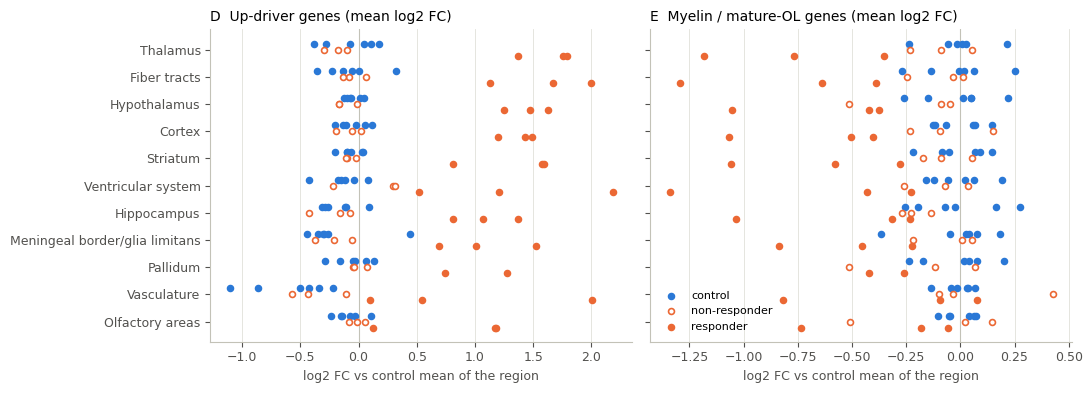

In [6]:
up_genes = [g for g in drivers.index[drivers.direction == "up"]]
dn_genes = [g for g in drivers.index[drivers.direction == "down"]]
selr = (m.cell_type == olr.OL) & (m.region != TISSUE_WIDE)
cr = pb.counts.loc[selr]; cprm = cr.div(cr.sum(1), axis=0) * 1e6
meta_r = m.loc[selr, ["sample_id", "region", "n_cells"]]
rows = []
for reg, idx in meta_r.groupby("region").groups.items():
    sub = cprm.loc[idx]; sids = meta_r.loc[idx, "sample_id"].to_numpy()
    base = sub[np.isin(sids, ctrl)].mean()
    l = np.log2((sub + 1) / (base + 1))
    for sid, (_, row) in zip(sids, l.iterrows()):
        rows.append({"region": reg, "sample_id": sid, "up_programme": row[up_genes].mean(), "myelin_down": row[dn_genes].mean()})
reg = pd.DataFrame(rows).merge(sections[["group"]], left_on="sample_id", right_index=True)
regsum = reg.pivot_table(index="region", columns="group", values=["up_programme", "myelin_down"], aggfunc="mean")
regsum = regsum.sort_values(("up_programme", "responder"), ascending=False)
save_table(regsum.round(3), "driver_programme_by_region")
display(regsum.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = regsum.index.tolist()
for ax, col, title in zip(axes, ["up_programme", "myelin_down"], ["D  Up-driver genes (mean log2 FC)", "E  Myelin / mature-OL genes (mean log2 FC)"]):
    for gi, g in enumerate(GROUP_ORDER):
        sub = reg[reg.group == g]
        y = sub.region.map({r: i for i, r in enumerate(order)}) + (gi - 1) * 0.22
        style = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE),
                 "responder": dict(color=ORANGE)}[g]
        ax.scatter(sub[col], y, s=18, linewidth=1.2, label=g, zorder=3, **style)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.set_title(title); ax.set_xlabel("log2 FC vs control mean of the region")
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
axes[0].set_yticks(range(len(order)), order); axes[0].invert_yaxis()
axes[1].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
save(fig, "G4_driver_programme_by_region")

## 5. Caveats checked

* **Glucocorticoid-response genes** (Sgk1, Fkbp5, Zbtb16, Plin4, Arrdc2) carry large classifier weights
  but show no within-section association and no responder pattern across sections (e.g. Sgk1 is highest
  in a control, RB4282). They track a section-level state (most likely stress / time of day at sacrifice)
  and are *not* counted as mtDSB drivers. This is why drivers are defined by the within-section rule.
* **Neuronal spill-over**: ratio of each driver's CPM in neurons vs oligodendrocytes in control sections;
  drivers enriched in neurons could reflect segmentation leakage.
* **Sex genes**: Xist carries a negative pooled weight (sex is not balanced across the training folds);
  it is not a driver.

In [7]:
gcx = cpm[[g for g in GLUCOCORTICOID if g in cpm.columns]].join(sections[["age", "group"]]).loc[sec_order]
save_table(gcx.round(1), "glucocorticoid_genes_by_section")
display(gcx.round(0))
display(asum.loc[[g for g in GLUCOCORTICOID if g in asum.index], ["weight[condition]", "r_responder", "r_control"]].round(3))

neuro = ["Neurons", "Excitatory Neurons", "GABAergic Neurons", "Medium Spiny Neurons"]
selc = m.region.eq(TISSUE_WIDE) & m.sample_id.isin(ctrl)
def type_cpm(types):
    s = pb.counts.loc[selc & m.cell_type.isin(types)].sum()
    return s / s.sum() * 1e6
ratio = np.log2((type_cpm(neuro) + 1) / (type_cpm([olr.OL]) + 1)).rename("log2_neuron_vs_OL_cpm")
drivers["log2_neuron_vs_OL_cpm"] = ratio.reindex(drivers.index)
drivers["neuron_enriched_flag"] = drivers["log2_neuron_vs_OL_cpm"] > 2
save_table(drivers.round(4), "driver_genes")
display(drivers.loc[drivers.neuron_enriched_flag, ["direction", "programme", "log2_neuron_vs_OL_cpm", "r_responder"]].round(2))

,Sgk1,Fkbp5,Zbtb16,Plin4,Arrdc2,Per1,Tsc22d3,age,group
sample_id,,,,,,,,,
RB4620,1197.0,90.0,396.0,615.0,308.0,117.0,849.0,21,control
RB4658,684.0,136.0,416.0,1553.0,328.0,78.0,1082.0,21,control
RB4676,281.0,56.0,232.0,178.0,298.0,43.0,732.0,21,control
RB4282,4450.0,119.0,569.0,619.0,425.0,162.0,1245.0,60,control
RB4350,2368.0,108.0,500.0,386.0,322.0,148.0,1196.0,60,control
RB4498,1204.0,84.0,429.0,392.0,256.0,99.0,1168.0,60,control
RB4630,2823.0,162.0,624.0,983.0,412.0,141.0,1084.0,21,non-responder
RB4653,2892.0,218.0,873.0,1972.0,627.0,146.0,1085.0,21,non-responder
RB4403,1119.0,119.0,387.0,274.0,208.0,120.0,1188.0,60,non-responder


,weight[condition],r_responder,r_control
gene,,,
Sgk1,0.434,-0.010,0.120
Fkbp5,0.201,0.100,0.068
Zbtb16,0.296,0.081,0.094
Plin4,0.259,0.041,0.097
Arrdc2,0.160,-0.029,0.039
Per1,0.102,0.074,0.041
Tsc22d3,0.016,-0.071,0.004


,direction,programme,log2_neuron_vs_OL_cpm,r_responder
gene,,,,
